In [1]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from scipy.special import jv
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import mpmath
from mpmath import *
import time
import pandas as pd
import matplotlib
import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolations_func import *
import AR_interpolations_func
importlib.reload(AR_interpolations_func)
from AR_interpolations_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolations_plotting import *
import AR_interpolations_plotting
importlib.reload(AR_interpolations_plotting)
from AR_interpolations_plotting  import *



fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Get Simulation data of exctinction spectra for different AR

In [2]:
dir_root_v3 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR_estimation\Simulations_treated'
fname_data_simu = 'Simulation_treated.csv'

#kernel = 'thin_plate_spline'
Simu_data, Lda_RBF, E_RBF, W_RBF, Aire_RBF = get_simu_data_and_interpolate(dir_root_v3, fname_data_simu, kernel='linear')

h_1D = 25


H_lisse = np.linspace(0, 40, 200)
D_lisse = np.linspace(0, 160, 200)
HH_lisse, DD_lisse = np.meshgrid( H_lisse, D_lisse)
points_lisses = np.array(list(zip(HH_lisse.flatten(), DD_lisse.flatten())))

C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\AR_interpolations_plotting.py:30: RuntimeWarning: divide by zero encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3], colors='black', alpha=0.6)
C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\AR_interpolations_plotting.py:30: RuntimeWarning: invalid value encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3], colors='black', alpha=0.6)


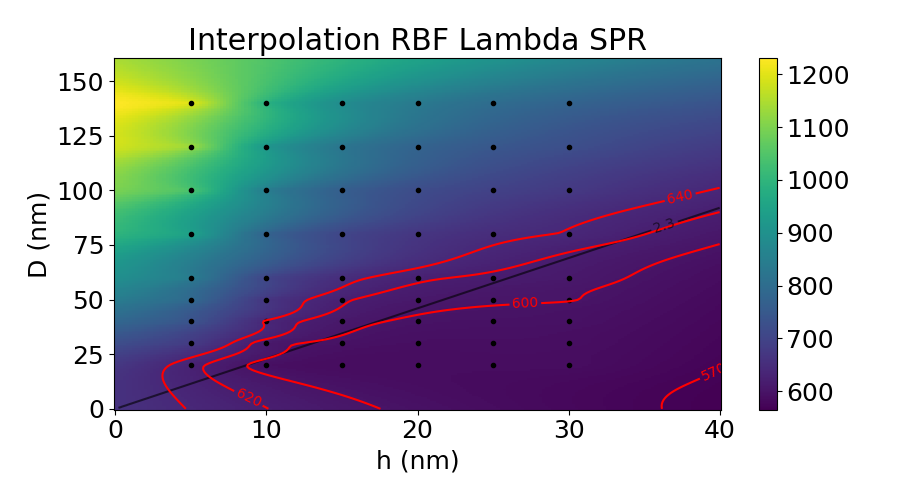

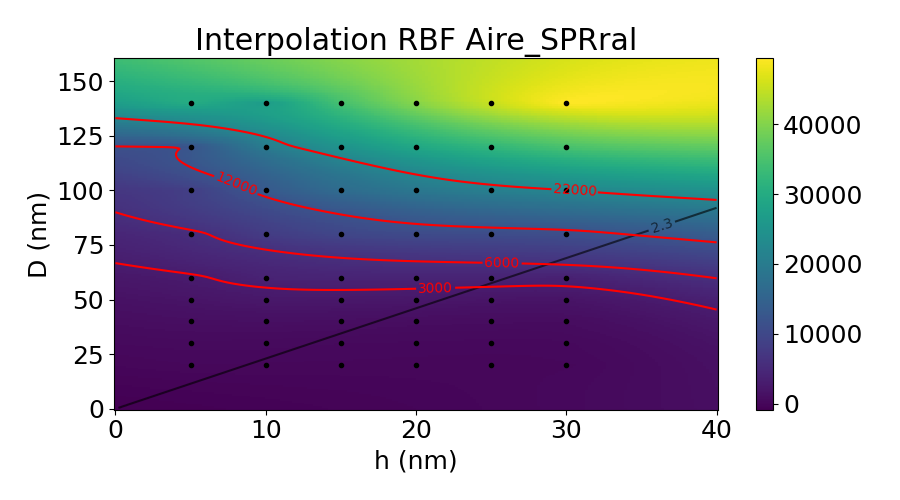

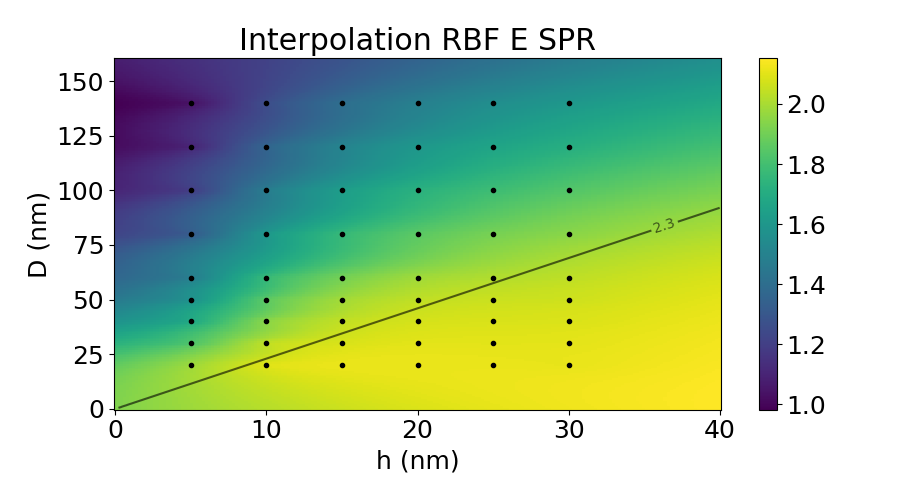

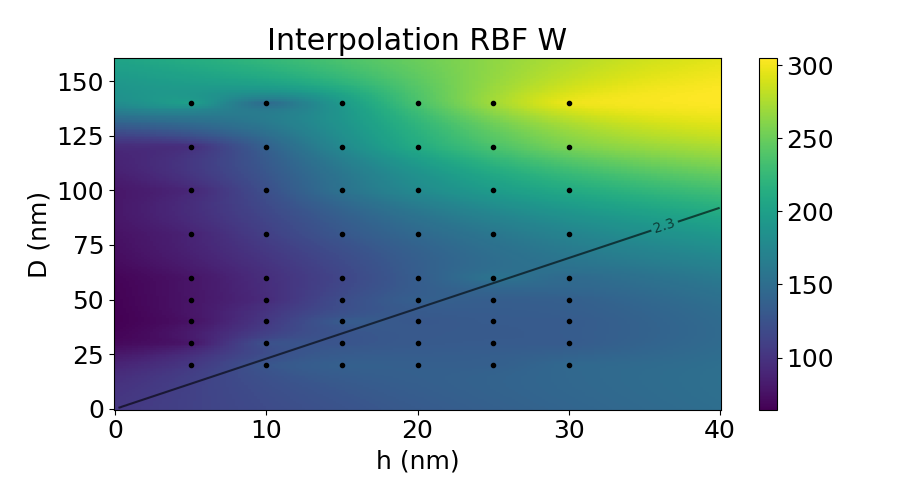

In [3]:
plot_func_interp(Lda_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='Lambda SPR', contour_specif=[570, 600, 620, 640])
plot_func_interp(Aire_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='Aire_SPRral', contour_specif=[3000,6000, 12000,22000])
plot_func_interp(E_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='E SPR')
plot_func_interp(W_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='W')

## Get experimental data of ND

In [ ]:
dir_root_ND = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR_estimation\ND_measurements'
fname_Exp = 'Nd_measurements_data.dat'
Exp_data = get_ND_measures(dir_root_ND, fname_Exp)

# for key in Exp_data :
#     print('----------------------------------------------')
#     for kkey in Exp_data[key] :
#         print(kkey, '///',  Exp_data[key][kkey])


## Estimate the AR of studied ND using simulation data

In [6]:
d_guess, h_guess = 80, 20 #initial (D,h) guess in nm

AR_estimation_1D_Lda_SPR(Exp_data, Lda_RBF, h=h_1D)
AR_estimation_1D_Aire_SPR(Exp_data, Aire_RBF, h=h_1D)
AR_estimation_2D(Exp_data, Lda_RBF, Aire_RBF, d_guess=d_guess, h_guess=h_guess)




Gamma_surf_estimation(Exp_data, W_RBF)

Erreur de convergence 1D sur 2.3 zone-Sylvie NDas58 avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone-Sylvie NDas73 avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone-Sylvie NDbs02 avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone-Sylvie NDbs14 avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone1 NDe avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone1 NDf avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone2 NDa avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone2 NDb avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone2 NDc avec le paramètre de fit : SPR position
Erreur de convergence 1D sur 2.3 zone2 NDe avec le paramètre de fit : SPR position
Erreur de convergence 2D sur : 2.3 zone-Sylvie NDbs02


plot f_red_with_AR

In [7]:
if 0 :
    fig, ax = plt.subplots()
    plot_f_red_AR(Exp_data, ax, h_1D)
    plt.tight_layout()
    plt.show()

plot 1D interpolation

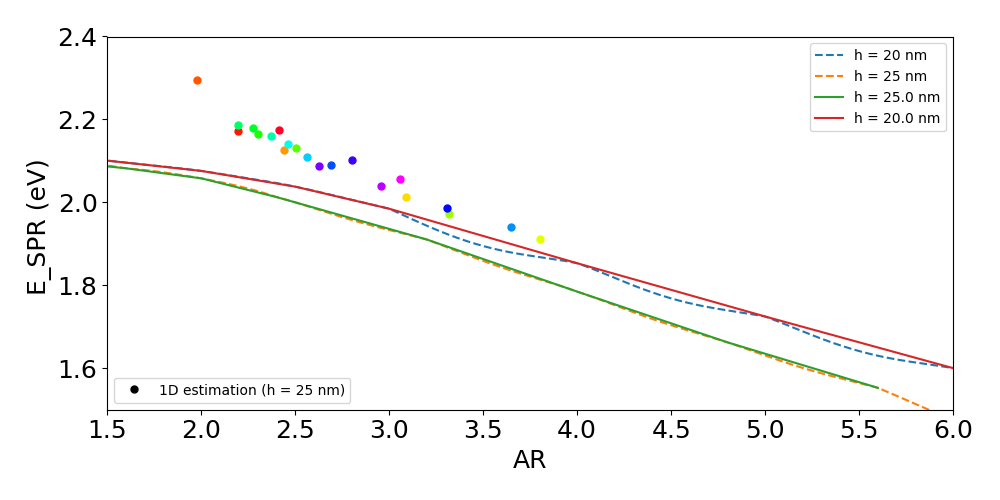

In [8]:
if 1 :
        
    fig, ax = plt.subplots(figsize=(10, 5))

    legend2 = plot_E_SPR_with_AR_simulation_prolongated(E_RBF, ax, h_list=[20, 25])
    #legend3 = plot_E_SPR_with_AR_fit_2D_and_1D_lda_SPR(Exp_data, ax, h_1D)
    legend3 = plot_E_SPR_with_AR_fit_1D_Aire(Exp_data, ax, h_1D)
    legend1 = plot_E_SPR_with_AR_simulation(Simu_data, ax, old_legend=legend3, h_list = [20, 25])

    plt.xlim((1.5, 6))
    plt.ylim((1.5, 2.4))
    plt.tight_layout()
    plt.show()

## Save data

In [ ]:
dir_save_data = r'\\helios.univ-lyon1.fr\femto-nano\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR_estimation\ND_measurements_AR_treated'

fname_1D = '1D_AR_interpolation_python_approach_h_{}.csv'.format(h_1D)
#save_1D_interpolation_to_csv(Exp_data, dir_save_data, fname_1D, h_1D)


fname_2D = '2D_AR_interpolation_python_approach.csv'.format(h_1D)
#save_2D_interpolation_to_csv(Exp_data, dir_save_data, fname_2D)

C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\AR_interpolations_plotting.py:254: RuntimeWarning: divide by zero encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3], colors='black', alpha=0.6)
C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\AR_interpolations_plotting.py:254: RuntimeWarning: invalid value encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3], colors='black', alpha=0.6)


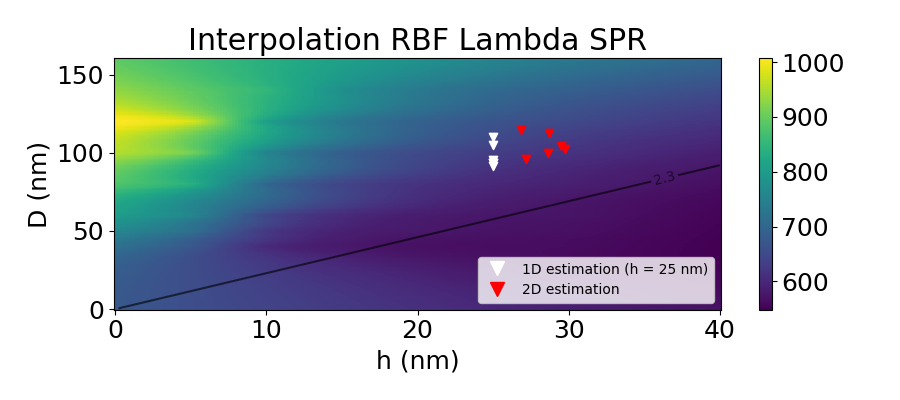

In [ ]:
plot_interpolation_result_2D(Lda_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Exp_data,contour_specif=[], title='Lambda SPR')

<>:12: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\l'
C:\Users\nberr\AppData\Local\Temp\ipykernel_7832\3038240487.py:12: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('$\lambda_{SPR}$ (nm)')


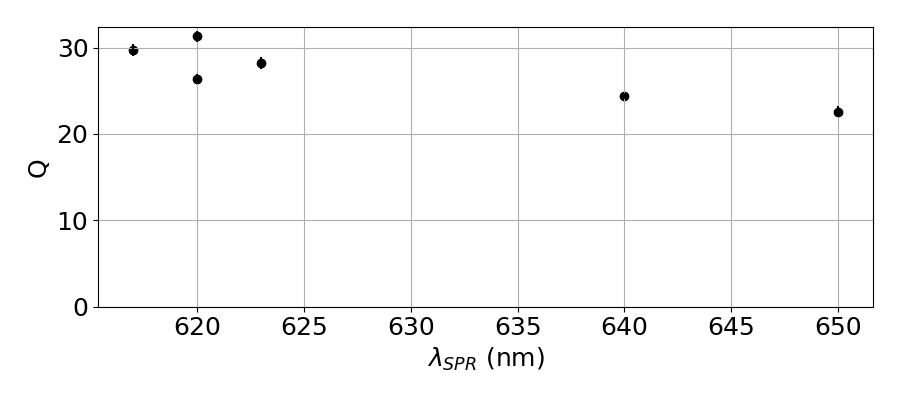

In [ ]:
fig, ax = plt.subplots(figsize = (9,4))

for key in Exp_data :
    spectra = Exp_data[key]

    if spectra['Q'] != 0 :
            
        ax.scatter(spectra['lda_SPR'], spectra['Q'], c = 'black')
        ax.errorbar(spectra['lda_SPR'], spectra['Q'], yerr = spectra['Q_err'], color='black')
        

ax.set_xlabel('$\lambda_{SPR}$ (nm)')
ax.set_ylabel('Q')
ax.set_ylim(bottom = 0)
ax.grid()
plt.tight_layout()
plt.show()
fig.patch.set_facecolor( '#FF000000' )
os.chdir(r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Quartz')

plt.savefig('test.png')
plt.savefig('test.pdf')

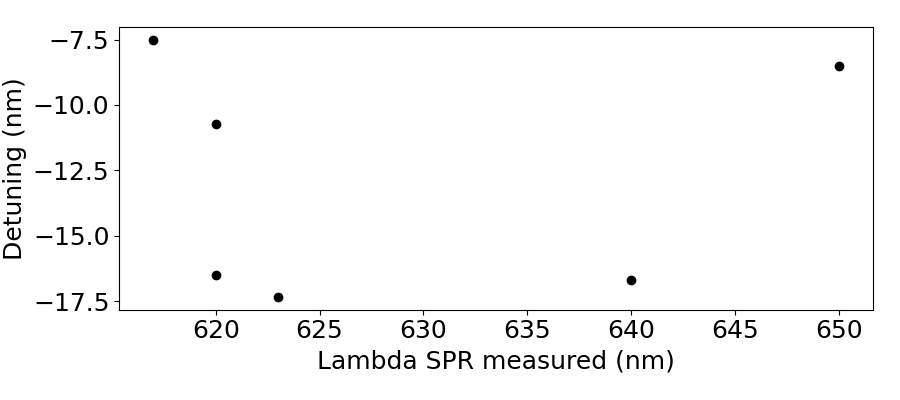

In [ ]:

fig, ax = plt.subplots(figsize=(9,4))


for key in Exp_data :
    spectra = Exp_data[key]
    lda_SPR_meas = spectra['lda_SPR']
    
    lda_SPR_interp = Lda_RBF([[h_1D, spectra['1D_estimation_Aire_SPR']['D']]])[0]

    ax.scatter(lda_SPR_meas, lda_SPR_meas - lda_SPR_interp , color='black' )
    #print(lda_SPR_interp - lda_SPR_meas )


ax.set_xlabel('Lambda SPR measured (nm)') 
ax.set_ylabel('Detuning (nm)')

plt.tight_layout()
plt.show()

In [ ]:
print(Lda_RBF([[21, 120]]))

[684.6829013]


In [ ]:
if 1 :
    for key in Exp_data :
        ND = Exp_data[key]
        print(ND['lda_SPR'],ND['Aire_SPR'] )
  

620.0 21700.0
623.0 25190.0
650.0 33200.0
620.0 23800.0
640.0 32200.0
617.0 19400.0
